# Google Play: Follow-up Checks (notebook 3)
Runs on `playstore_clean_dataset.csv` (from notebook 1). Two questions raised by the notebook 2 results.

**Check 1: which categories are well received?** Category is the strongest input. This table shows why.

**Check 2: is part of the signal post-launch drift?** Ads, in-app purchases and size are the **June 2021 listing**, not launch values. Successful games tend to add monetisation and content over time, so these fields may look predictive partly because the game already succeeded. We cannot see launch-time values, but we can compare games by **how long they had been on the store at the scrape date**. Games released a few months before the scrape had little time to change. If the extra signal from the listing fields (full model minus a category-only model) is just as large for them, drift is unlikely to be the main explanation. If it is clearly smaller or near zero for new games, drift is a plausible explanation.

How it works: one set of developer-grouped out-of-fold predictions for each of two models (category + content rating only, and all 12 inputs), then AUC per age bucket, with a 95% interval from resampling **developers** (not rows).

Caveats: new games with at least 50 ratings are a different, more popular subset; the label base rate differs by bucket; release dates are the store's and 1.7% are missing (left out here). This is evidence about drift, not proof.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier
warnings.filterwarnings('ignore'); pd.set_option('display.width', 200)

DATA = 'playstore_clean_dataset.csv'
RANDOM_STATE, N_SPLITS, N_BOOT = 42, 5, 300
SCRAPE_DATE = pd.Timestamp('2021-06-16')
CAT = ['category', 'content_rating']
ALL = CAT + ['free', 'price_usd', 'ad_supported', 'in_app_purchases', 'size_mb', 'min_android', 'has_website', 'has_privacy', 'size_was_missing', 'min_android_was_missing']
df = pd.read_csv(DATA, parse_dates=['release_date'])
ALL = [c for c in ALL if c in df.columns]
y = df['label'].values; groups = df['developer_hash'].values
print(f'{len(df):,} games | well received {y.mean()*100:.1f}%')

109,363 games | well received 60.0%


## Check 1: well-received rate by category

,games,well received %,% of dataset
category,,,
Simulation,13384,44.3,12.2
Racing,4530,50.4,4.1
Action,9863,52.0,9.0
Music,1545,53.9,1.4
Strategy,3646,56.6,3.3
Casual,13160,57.1,12.0
Role Playing,6126,59.8,5.6
Adventure,9113,59.8,8.3
Arcade,10376,60.2,9.5


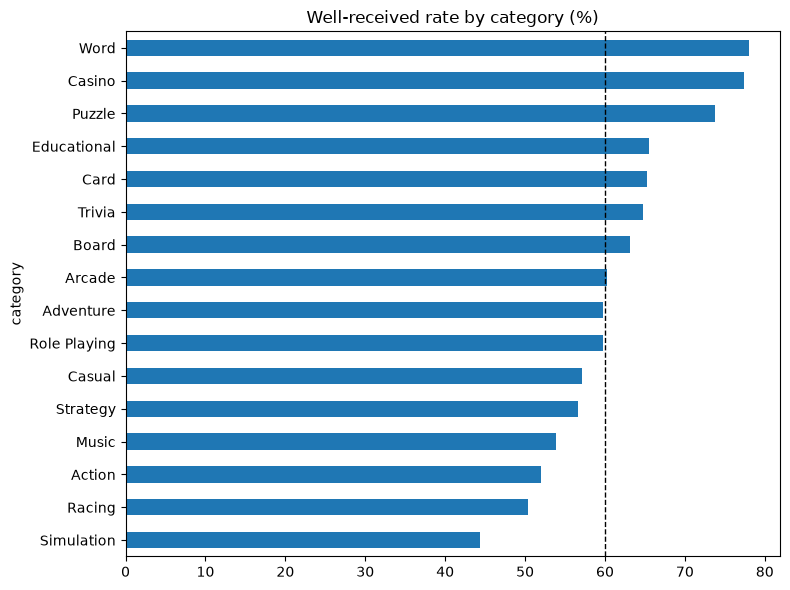

In [2]:
t = (df.groupby('category')['label'].agg(games='size', well_received='mean').assign(share_of_dataset=lambda x: x['games'] / len(df))
       .sort_values('well_received'))
t['well_received'] = (t['well_received'] * 100).round(1); t['share_of_dataset'] = (t['share_of_dataset'] * 100).round(1)
display(t.rename(columns={'well_received': 'well received %', 'share_of_dataset': '% of dataset'}))
ax = t['well_received'].plot.barh(figsize=(8, 6), title='Well-received rate by category (%)'); ax.axvline(df['label'].mean() * 100, color='k', ls='--', lw=1)
plt.tight_layout(); plt.show()

## Check 2: out-of-fold predictions for two models

In [3]:
def make_model(cat_cols):
    return CatBoostClassifier(depth=4, learning_rate=0.1, iterations=500, l2_leaf_reg=5, auto_class_weights='Balanced',
                              cat_features=cat_cols, random_seed=RANDOM_STATE, verbose=0, thread_count=4)

skf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(df, y, groups))
oof = {}
for name, cols in [('category_only', CAT), ('full', ALL)]:
    p = np.zeros(len(df))
    for tr, te in folds:
        m = make_model([c for c in CAT if c in cols]); m.fit(df.loc[tr, cols], y[tr])
        p[te] = m.predict_proba(df.loc[te, cols])[:, 1]
    oof[name] = p
    print(f'{name}: overall out-of-fold AUC {roc_auc_score(y, p):.4f}')

category_only: overall out-of-fold AUC 0.6106
full: overall out-of-fold AUC 0.6657


## Check 2: AUC by how long the game had been on the store at the scrape date

In [4]:
d = df.dropna(subset=['release_date']).copy()
d['age_months'] = (SCRAPE_DATE - d['release_date']).dt.days / 30.44
d = d[d['age_months'] >= 0]
bins = [0, 6, 12, 24, 36, 1e9]; labels = ['<6 months', '6-12 months', '1-2 years', '2-3 years', '3+ years']
d['bucket'] = pd.cut(d['age_months'], bins=bins, labels=labels, right=False)
d['p_cat'] = oof['category_only'][d.index]; d['p_full'] = oof['full'][d.index]
print(f'games with a usable release date: {len(d):,} of {len(df):,} (left out: {len(df)-len(d):,})')

dev_codes, dev_uni = pd.factorize(d['developer_hash']); n_dev = len(dev_uni)
rng = np.random.default_rng(0)
rows = []
for b in labels:
    s = d[d['bucket'] == b]
    if len(s) < 200 or s['label'].nunique() < 2:
        rows.append({'age at scrape': b, 'games': len(s), 'note': 'too few to score'}); continue
    idx = s.index.values; yy = s['label'].values; pc = s['p_cat'].values; pf = s['p_full'].values
    dc = dev_codes[d.index.get_indexer(idx)]
    a_c, a_f = roc_auc_score(yy, pc), roc_auc_score(yy, pf)
    gains = []
    for _ in range(N_BOOT):
        cnt = np.bincount(rng.integers(0, n_dev, n_dev), minlength=n_dev)   # resample developers
        w = cnt[dc]
        if w.sum() == 0 or len(np.unique(yy[w > 0])) < 2: continue
        gains.append(roc_auc_score(yy, pf, sample_weight=w) - roc_auc_score(yy, pc, sample_weight=w))
    lo, hi = np.percentile(gains, [2.5, 97.5])
    rows.append({'age at scrape': b, 'games': len(s), 'well received %': round(s['label'].mean() * 100, 1),
                 'AUC category only': round(a_c, 3), 'AUC full model': round(a_f, 3), 'gain': round(a_f - a_c, 3),
                 'gain 95% low': round(lo, 3), 'gain 95% high': round(hi, 3)})
R = pd.DataFrame(rows); display(R)

games with a usable release date: 107,521 of 109,363 (left out: 1,842)


,age at scrape,games,well received %,AUC category only,AUC full model,gain,gain 95% low,gain 95% high
0,<6 months,6205,68.4,0.621,0.646,0.025,0.009,0.040
1,6-12 months,9948,61.8,0.619,0.666,0.047,0.036,0.059
2,1-2 years,17695,60.0,0.615,0.663,0.047,0.038,0.056
3,2-3 years,14969,59.3,0.633,0.670,0.037,0.026,0.047
4,3+ years,58704,59.0,0.607,0.669,0.062,0.055,0.070


## Reading the table (fill in after the run)
- **Gain** = AUC of the full model minus AUC of the category-only model, i.e. what the listing fields add.
- If the gain in the newest buckets (<6 and 6-12 months) is about the same as in the older ones, post-launch drift is unlikely to be the main source of the extra signal. If it is clearly smaller, or its interval includes 0 while older buckets do not, drift is a plausible explanation. Say which, and say it is an inference.
- Look at the overlap of the intervals before saying two buckets differ. Small buckets have wide intervals.
- Whatever the result, the report still states that these fields are 2021 listing values.